# 01 Preprocessing

This notebook cleans the merged anime data and creates the dataset that the rest of the project uses.

**The data.** The dataset combines two public MyAnimeList sources. Ratings, user attributes and timestamps come from the 2018 MyAnimeList Dataset [1]. Synopsis text comes from the 2020 Anime Recommendation Database [2]. No single source had all four kinds of data the project needs, so the synopsis was joined to the 2018 data on the anime ID. The merge is done in `00_build_dataset.ipynb`. It keeps every interaction and gives a synopsis to 99.1% of them.

**What this notebook does**

1. Data quality checks that look for problems in the merged data
2. Cleaning, where each step fixes a problem found in the checks
3. A sample of users for modelling, saved to `data/processed`

The exploration of the clean data is in `02_eda.ipynb`.

In the anime lists, each row is one user and one anime. `score` is the rating from 1 to 10, where 0 means the user did not rate it. `status` is where the anime is on the user's list. The codes are 1 watching, 2 completed, 3 on hold, 4 dropped and 6 plan to watch.

In [1]:
%pip install -q pandas pyarrow matplotlib pycountry

Note: you may need to restart the kernel to use updated packages.


In [2]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pycountry

# Set a concrete seed to make results reproducible
import random
my_seed = 1234
random.seed(my_seed)
np.random.seed(my_seed)

## 1. Load the data

The interactions table has 31 million rows. To keep it small enough for a laptop, it is loaded one file at a time and the number columns are stored as smaller types. A score from 0 to 10 does not need 64 bits.

In [3]:
small_types = {
    "user_id": "int32",
    "anime_id": "int32",
    "score": "int8",
    "status": "int8",
    "watched_episodes": "int32",
}

def load_interactions(columns):
    parts = []
    for path in sorted(glob.glob("../data/merged/interactions/*.parquet")):
        part = pd.read_parquet(path, columns=columns)
        part = part.astype({col: small_types[col] for col in columns if col in small_types})
        parts.append(part)
    return pd.concat(parts, ignore_index=True)

interactions_df = load_interactions(
    ["user_id", "anime_id", "score", "status", "watched_episodes", "last_updated"]
)
anime_df = pd.read_parquet("../data/merged/anime.parquet")
users_df = pd.read_parquet("../data/merged/users.parquet")

print(f"Memory used by the interactions: {interactions_df.memory_usage().sum() / 1e9:.2f} GB")
interactions_df.head()

Memory used by the interactions: 0.69 GB


,user_id,anime_id,score,status,watched_episodes,last_updated
0,2255153,21,9,1,586,2013-03-03 10:52:53
1,2255153,59,7,2,26,2013-03-10 13:54:51
2,2255153,74,7,2,26,2013-04-27 16:43:35
3,2255153,120,7,2,26,2013-03-03 10:53:57
4,2255153,178,7,2,26,2013-03-27 15:59:13


## 2. Data quality checks

In [4]:
def basic_stats(df, user_col, item_col):
    n_rows = df.shape[0]
    n_users = df[user_col].nunique()
    n_items = df[item_col].nunique()
    print(f"There are {n_rows} interactions from {n_users} users to {n_items} anime")
    return n_rows, n_users, n_items

basic_stats(interactions_df, "user_id", "anime_id");

There are 31284030 interactions from 108710 users to 6668 anime


### Duplicates and missing values

In [5]:
# One number per user and anime pair (anime ids are below 100,000), which uses less memory than comparing two columns
pair_key = interactions_df["user_id"].astype("int64") * 100_000 + interactions_df["anime_id"]
print("Duplicate user and anime pairs:", pair_key.duplicated().sum())
del pair_key

print()
print("Share of missing values in the interactions")
print(interactions_df.isna().mean().round(3))

Duplicate user and anime pairs: 0

Share of missing values in the interactions
user_id             0.0
anime_id            0.0
score               0.0
status              0.0
watched_episodes    0.0
last_updated        0.0
dtype: float64


In [6]:
# start_date and finish_date are only loaded here to see how often they are filled
dates_df = load_interactions(["start_date", "finish_date"])
print("Share of missing start_date:", round(dates_df["start_date"].isna().mean(), 3))
print("Share of missing finish_date:", round(dates_df["finish_date"].isna().mean(), 3))
del dates_df

Share of missing start_date: 0.85
Share of missing finish_date: 0.816


**`last_updated` is the only usable timestamp.** `start_date` and `finish_date` are missing in 85% and 82% of the rows, while `last_updated` is filled for every row. Time-based evaluation (CVTT) and context-aware models need a timestamp for every rating, since each rating has to be placed before or after a cut-off date [5, pp. 26-27]. Only `last_updated` makes that possible.

One could argue that the start and finish dates are more accurate, since they record when the anime was actually watched. But they exist for less than a fifth of the rows, and the users who fill them in are a self-selected, more engaged group, so a model built on them would not represent the typical user. `last_updated` is used instead, with the known limit that it is the moment of the last edit, not of watching.

In [7]:
print("Missing values in the anime table")
print(anime_df.isna().sum())

Missing values in the anime table
anime_id              0
title                 0
title_english      3230
type                  0
source                0
episodes              0
rating               82
score                 0
scored_by             0
popularity            0
members               0
premiered          3702
studio                0
genre                 4
duration_min          0
aired_from_year       0
synopsis            345
dtype: int64


**Every anime stays in the catalog, including those without a synopsis.** Only four anime have no genre, and 345 (5.2%) have no synopsis because they had no match in the 2020 source. A content-based recommender needs a text column, and works better when the text is combined with categorical features [8, p. 1]. Title, genre and type exist for every anime, so the anime without a synopsis can still be described and recommended.

Removing them would make the text models simpler, but it would also remove anime that users rated, which the collaborative filtering models need. These anime cover only 0.9% of the interactions (00_build_dataset), so keeping them costs little.

`title_english` is empty for 48% of the anime because many only have a Japanese title, which is in `title`. `premiered` is empty for 56% because only TV series air in a season. The release year is in `aired_from_year`. Neither column is needed, so both are dropped in the cleaning.

In [8]:
print("Missing values in the users table")
print(users_df.isna().sum())

Missing values in the users table
user_id       0
gender        0
location      5
birth_date    0
join_date     0
dtype: int64


### Status codes

In [9]:
interactions_df["status"].value_counts().sort_index()

status
0          167
1      1558384
2     19946276
3      1186648
4      1230250
5            4
6      7362297
33           3
55           1
Name: count, dtype: int64

Codes 0, 5, 33 and 55 are not MyAnimeList statuses. They appear in 175 rows and are removed in the cleaning. Mapping them to the nearest valid status would be guessing, since their meaning is not documented. Most entries are completed anime (64%), followed by plan to watch (24%).

### Dates

First last_updated: 1970-01-01 00:00:00
Last last_updated: 2018-05-22 07:49:06


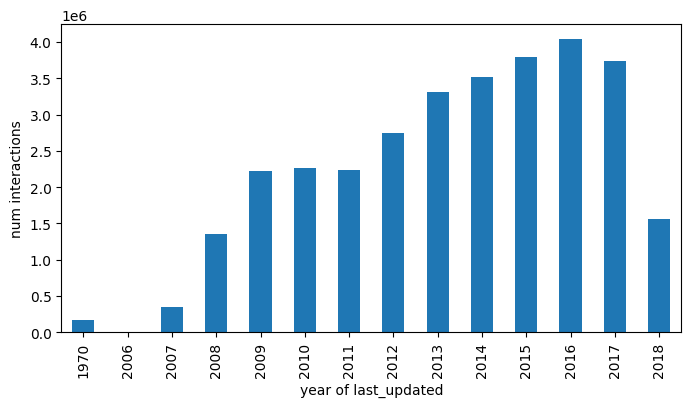

In [10]:
print("First last_updated:", interactions_df["last_updated"].min())
print("Last last_updated:", interactions_df["last_updated"].max())

plt.figure(figsize=(8, 4))
interactions_df.groupby(interactions_df["last_updated"].dt.year).size().plot.bar();
plt.xlabel("year of last_updated");
plt.ylabel("num interactions");

**The 163,231 rows dated 1970-01-01 have no real timestamp.** The data otherwise runs from 2006 to May 2018, and 1 January 1970 is the start of Unix time, the value a missing timestamp gets when it is stored as zero. In a time-based split these rows would all count as the oldest ratings and end up in every training fold [5, p. 27], which would distort the evaluation. They are 0.5% of the data, so they are removed rather than kept only for the models that ignore time. One dataset for every model keeps all results comparable.

### Scores per status

In [11]:
status_names = {1: "watching", 2: "completed", 3: "on hold", 4: "dropped", 6: "plan to watch"}

rated_share = (interactions_df["score"] > 0).groupby(interactions_df["status"]).mean()
rated_share = rated_share[rated_share.index.isin(status_names.keys())]
rated_share.index = rated_share.index.map(status_names)

print(f"Share of interactions without a score: {(interactions_df['score'] == 0).mean():.3f}")
print()
print("Share of interactions with a score, per status")
print(rated_share.round(3))

Share of interactions without a score: 0.387

Share of interactions with a score, per status
status
watching         0.352
completed        0.876
on hold          0.354
dropped          0.513
plan to watch    0.014
Name: score, dtype: float64


**Two kinds of feedback are mixed in the data.** 39% of the interactions have no score, and whether a user rates depends on the status. 88% of completed anime have a score, against only 1.4% of plan to watch entries. The score is explicit feedback, a deliberate opinion that only exists when the user makes the effort to give it. The status is implicit feedback, deduced from what the user does [3, p. 83]. Both are useful, but they have to be kept apart, because a missing score is not a bad score.

The 1.4% of plan to watch entries with a score are a problem. Plan to watch means the user has not seen the anime, so the score cannot be an opinion about watching it. This is fixed in the cleaning.

### User location and age

In [12]:
last_part = users_df["location"].str.split(",").str[-1].str.strip()

print("Different values after the last comma:", last_part.nunique())
print(last_part.value_counts().head(25))

Different values after the last comma: 20060
location
Poland         3562
California     2731
Canada         2272
Brazil         2143
Germany        2084
Philippines    2000
Australia      1625
Russia         1562
Brasil         1490
France         1482
England        1433
Portugal       1407
Indonesia      1370
Texas          1227
Sweden         1217
Florida         996
New York        995
UK              954
Finland         930
Italy           930
USA             927
Norway          851
Romania         781
Netherlands     748
Spain           745
Name: count, dtype: int64


**Location cannot be used for demographic filtering as it is.** Taking the text after the last comma as the country, as in the course example [4, p. 25], gives 20,060 different values here. Countries, US states, cities, abbreviations and spelling variants are mixed, such as Brazil and Brasil or UK and England. A demographic recommender groups users by their attributes and computes popularity per group [7, p. 2]. With this column most groups would be a single user, so it is cleaned into a country in the cleaning.

In [13]:
end_of_data = interactions_df["last_updated"].max()
age = (end_of_data - users_df["birth_date"]).dt.days / 365.25
print(age.describe().round(1))

count    108711.0
mean         25.0
std           4.6
min           9.4
25%          21.8
50%          24.7
75%          27.8
max          49.4
Name: birth_date, dtype: float64


Age at the end of the data (May 2018) ranges from 9 to 49 years, with a median of 24.7. Birth dates are self-reported and cannot be verified. But there are no impossible values, and a young median fits an anime website, so age is used as it is.

## 3. Cleaning

Each step below fixes a problem found in the checks. The number of rows is printed after each step so the effect of every decision is visible.

In [14]:
invalid_status = ~interactions_df["status"].isin(status_names.keys())
fake_date = interactions_df["last_updated"].dt.year == 1970

print("Interactions with an invalid status code:", invalid_status.sum())
print("Interactions with the fake 1970 date:", fake_date.sum())

clean_df = interactions_df[~invalid_status & ~fake_date]
print("Interactions left:", len(clean_df))

# The full table is no longer needed, so it is removed to free memory
del interactions_df, invalid_status, fake_date

Interactions with an invalid status code: 175
Interactions with the fake 1970 date: 163231


Interactions left: 31120705


The rows with an invalid status and the rows with the 1970 date are removed, for the reasons in the checks above. Together this is 0.5% of the data.

In [15]:
plan_to_watch_with_score = (clean_df["status"] == 6) & (clean_df["score"] > 0)
print("Plan to watch entries with a score:", plan_to_watch_with_score.sum())

clean_df.loc[plan_to_watch_with_score, "score"] = 0

Plan to watch entries with a score: 104667


**Scores on plan to watch entries are set to 0 instead of removing the rows.** A rating is only useful if it reflects the user's opinion of the item, and even real ratings do not always do that [3, p. 83]. A score on an anime the user has not watched yet is at best an expectation. Removing the 104,667 rows would also lose the implicit signal that the user is interested.

It is possible that some users watched the anime before and listed it as plan to watch by mistake. But the data cannot tell which ones, and the status is the only record of what the user says they did. After this step there is one simple rule for the whole project. A row is an explicit rating when `score` is above 0.

In [16]:
anime_df = anime_df.drop(columns=["title_english", "premiered"])

`title_english` and `premiered` are dropped for the reason given in the anime check. The remaining gaps in the anime table are the 345 missing synopses and 82 missing age ratings.

### Users: country and age

In [17]:
country_names = {}
for country in pycountry.countries:
    country_names[country.name.lower()] = getattr(country, "common_name", country.name)

us_states = [state.name.lower() for state in pycountry.subdivisions.get(country_code="US")]

# Common spellings, cities and regions that do not match an official country name
aliases = {
    "usa": "United States", "us": "United States", "america": "United States",
    "united states of america": "United States",
    "uk": "United Kingdom", "england": "United Kingdom", "scotland": "United Kingdom",
    "wales": "United Kingdom", "great britain": "United Kingdom", "london": "United Kingdom",
    "brasil": "Brazil", "são paulo": "Brazil", "rio de janeiro": "Brazil", "minas gerais": "Brazil",
    "russia": "Russian Federation", "moscow": "Russian Federation", "saint-petersburg": "Russian Federation",
    "the netherlands": "Netherlands", "holland": "Netherlands", "nederland": "Netherlands",
    "polska": "Poland", "warsaw": "Poland",
    "españa": "Spain", "barcelona": "Spain", "madrid": "Spain",
    "méxico": "Mexico", "italia": "Italy", "deutschland": "Germany",
    "turkey": "Türkiye", "istanbul": "Türkiye", "czech republic": "Czechia",
    "ontario": "Canada", "alberta": "Canada", "quebec": "Canada", "british columbia": "Canada", "toronto": "Canada",
    "uae": "United Arab Emirates", "south korea": "Korea, Republic of", "korea": "Korea, Republic of",
    "vietnam": "Viet Nam", "jakarta": "Indonesia", "manila": "Philippines", "tokyo": "Japan",
    "sydney": "Australia", "melbourne": "Australia", "paris": "France",
}

def clean_country(location):
    last = str(location).split(",")[-1].strip().lower()
    if last in aliases:
        return aliases[last]
    if last in country_names:
        return country_names[last]
    if last in us_states:
        return "United States"
    return "Unknown"

users_df["country"] = users_df["location"].apply(clean_country)
print(f"Share of users with a recognised country: {(users_df['country'] != 'Unknown').mean():.3f}")

Share of users with a recognised country: 0.642


In [18]:
# Countries with fewer than 200 users are grouped as Other
country_counts = users_df["country"].value_counts()
small_countries = country_counts[country_counts < 200].index
users_df.loc[users_df["country"].isin(small_countries), "country"] = "Other"

print(users_df["country"].value_counts())

country
Unknown               38938
United States         16632
Brazil                 4633
Poland                 4080
United Kingdom         3958
Other                  3652
Canada                 3578
Philippines            2397
Russian Federation     2202
Germany                2158
Australia              1927
Netherlands            1826
France                 1698
Indonesia              1676
Portugal               1441
Sweden                 1273
Spain                  1199
Italy                  1095
Finland                 945
Norway                  878
Romania                 798
Japan                   733
India                   709
Singapore               699
Türkiye                 658
Malaysia                645
Hungary                 594
Bulgaria                587
Belgium                 568
Greece                  527
Denmark                 501
Argentina               478
Mexico                  470
Lithuania               439
Georgia                 437
New Zealand 

**Each location is matched to a country, and small countries are grouped.** The matching uses the official country list, a list of US states and a short list of common spellings and cities. This gives a country for 64% of the users. The rest, like "Earth" or "Wonderland", cannot be matched and becomes Unknown.

Countries with fewer than 200 users become Other. A popularity list per country is only reliable when it rests on enough ratings, which is the same problem the Bayesian average addresses for items with few ratings [7, p. 2]. A list built from a handful of users would mostly reflect their personal taste. Keeping every country would give more detail, but those small groups would produce popularity lists that are mostly noise.

In [19]:
users_df["age"] = age.round().astype(int)
users_df["age_group"] = pd.cut(
    users_df["age"],
    bins=[0, 17, 22, 27, 32, 100],
    labels=["under 18", "18-22", "23-27", "28-32", "33 and over"],
)
print(users_df["age_group"].value_counts().sort_index())

age_group
under 18        3647
18-22          29607
23-27          45998
28-32          23205
33 and over     6254
Name: count, dtype: int64


Age is grouped because demographic filtering computes popularity per group of users [7, p. 2], and a single age has too few users in the sample to give a stable list. The youngest and oldest groups are wider because they have few users.

### Users with too few ratings

In [20]:
clean_ratings_per_user = clean_df[clean_df["score"] > 0].groupby("user_id").size()
eligible_users = clean_ratings_per_user[clean_ratings_per_user >= 10].index

print("Users with at least one rating:", len(clean_ratings_per_user))
print("Users with at least 10 ratings:", len(eligible_users))

Users with at least one rating: 106330
Users with at least 10 ratings: 98177


**Users need at least 10 ratings to be part of the modelling data.** This keeps 98,177 of the 106,330 users with ratings and removes 8,153 (7.7%).

The reason is that each user needs enough test ratings to be evaluated. With 20% of the ratings in the test set, a user with fewer than 10 ratings has at most one or two test ratings. NDCG cannot be computed for a user with a single test item [5, p. 25], and with only two items a ranking can hardly be wrong, which inflates the ranking metrics of every recommender [6, pp. 14-15]. Users with too few ratings also make mean average precision unreliable [3, p. 240].

The counterargument is that these light users are real customers, and the system has to work for them too. They are not ignored. The cold start case is tested in a controlled way by hiding the history of selected users and checking what the system recommends to them. Anime are not filtered. Rare anime are exactly what a content-based model can recommend without ratings, so they stay in the catalog.

## 4. Sample of users for modelling

In [21]:
sampled_users = np.random.choice(eligible_users, size=5000, replace=False)
sample_df = clean_df[clean_df["user_id"].isin(sampled_users)].reset_index(drop=True)

basic_stats(sample_df, "user_id", "anime_id")
print("Ratings in the sample:", (sample_df["score"] > 0).sum())

There are 1539231 interactions from 5000 users to 6352 anime
Ratings in the sample: 977062


In [22]:
# Check that the sample looks like the full data
full_ratings = clean_df.loc[clean_df["score"] > 0, "score"]
sample_ratings = sample_df.loc[sample_df["score"] > 0, "score"]
comparison = pd.DataFrame({
    "full data": full_ratings.value_counts(normalize=True).sort_index(),
    "sample": sample_ratings.value_counts(normalize=True).sort_index(),
})
print(comparison.round(3))
print()
print("Mean rating, full data:", round(full_ratings.mean(), 2), " sample:", round(sample_ratings.mean(), 2))

sample_users_df = users_df[users_df["user_id"].isin(sampled_users)]
print()
print(pd.DataFrame({
    "full data": users_df.loc[users_df["user_id"].isin(eligible_users), "gender"].value_counts(normalize=True),
    "sample": sample_users_df["gender"].value_counts(normalize=True),
}).round(3))

       full data  sample
score                   
1          0.005   0.006
2          0.007   0.007
3          0.012   0.013
4          0.025   0.026
5          0.057   0.058
6          0.111   0.111
7          0.221   0.223
8          0.253   0.253
9          0.180   0.178
10         0.130   0.127



Mean rating, full data: 7.59  sample: 7.56

            full data  sample
gender                       
Male            0.667   0.662
Female          0.329   0.333
Non-Binary      0.005   0.005


**A random sample of 5,000 users is used for modelling.** The full data has 98,177 users and 19 million ratings. Memory-based collaborative filtering compares every user with every other user, so its similarity matrix grows with the square of the number of users. That is 25 million entries for 5,000 users, but about 9.6 billion for 98,177, far more than a laptop can hold. Working on a sample during development is also the recommended practice for large datasets [9, Session 19]. The sample keeps 977,062 ratings. Because users are sampled at random with their full history, every sampled user can be split into train and test.

The sample is representative. The rating distribution, the mean rating (7.56 against 7.59) and the gender split are almost identical to the full data.

The cost is that collaborative filtering learns from less data, and recommenders generally improve with more training data [5, pp. 14-15]. So the absolute results are slightly pessimistic. The comparison between models is not affected, since all of them use the same sample. The sample size can be raised for the final model if needed.

## 5. Save the final dataset

In [23]:
final_users_df = users_df.loc[
    users_df["user_id"].isin(sampled_users),
    ["user_id", "gender", "country", "age", "age_group", "join_date"],
]

os.makedirs("../data/processed", exist_ok=True)
sample_df.to_parquet("../data/processed/interactions.parquet", index=False)
final_users_df.to_parquet("../data/processed/users.parquet", index=False)
anime_df.to_parquet("../data/processed/anime.parquet", index=False)

print("interactions:", sample_df.shape)
print("users:", final_users_df.shape)
print("anime:", anime_df.shape)

interactions: (1539231, 6)
users: (5000, 6)
anime: (6668, 15)


**The final dataset in `data/processed`**

- `interactions.parquet` has one row per user and anime, with `score`, `status`, `watched_episodes` and `last_updated`. A row is an explicit rating when `score` is above 0. All other rows are implicit feedback.
- `users.parquet` has gender, country, age, age group and join date for the 5,000 sampled users.
- `anime.parquet` has the full catalog of 6,668 anime with metadata and synopsis.

Things to keep in mind when using the data. `last_updated` is when the user last changed the entry, not when they watched the anime. The data ends in May 2018. 345 anime have no synopsis and 36% of users have the country Unknown.

## References

[1] Račinský, M. (2018). MyAnimeList Dataset. Kaggle. https://doi.org/10.34740/KAGGLE/DSV/45582

[2] Valdivieso, H. Anime Recommendation Database 2020. GitHub. https://github.com/Hernan4444/MyAnimeList-Database

[3] Falk, K. (2019). Practical Recommender Systems. Manning.

[4] S05 notebook. Key data for building recommendation systems.

[5] S10 notebook. Data splitting and evaluation methods.

[6] Impact of long-tail into performance metrics notebook.

[7] A4 Build your own non-personalized recommender (assignment brief).

[8] A6 Build your own content-based recommender (assignment brief).

[9] Class notes (sessions as indicated).